#### "Flooding disrupts mobility networks, causing populations to lose simultaneous access to multiple urban functions. The accumulation of these losses creates cascading urban impacts and spatial isolation."

## This script:

1. Where do people live? How many people live there
2. What are the critical services that they use / we want to explore?
3. Prepring the road network
4. Baseline accessibility using accessibility metrics:


## 1. Where do people live? How many people live there

In [1]:
# imports

import warnings
warnings.simplefilter('ignore', FutureWarning)
import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import shapely
import igraph as ig
from pathlib import Path
from exactextract import exact_extract
import geohexgrid as ghg
from shapely.strtree import STRtree
import pyarrow 

import matplotlib.pyplot as plt
import contextily as cx
from matplotlib.colors import ListedColormap
from damagescanner.osm import _extract_value  # requires to pip install this package (rhttps://github.com/VU-IVM/DamageScanner). MUST BE LATEST DEV VERSION! (Pypi release is outdated.)

from snkit.network import Network, add_endpoints, split_edges_at_nodes, add_ids, add_topology

from simplify import * # requires to pip install osm-flex first. Python file simplify.py must be in the same folder as this notebook.
from pyproj import Geod

from functions import * 

warnings.simplefilter(action='ignore', category=FutureWarning)

c:\Users\gunaratn\AppData\Local\miniforge3\envs\MS2P_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Define root directory and network directory path
# the study area should be in the network directory, and the network directory should be in the root directory

root_dir = Path(r"P:\11212759-001-brs\002-Kaartverhal_KEA\MS2\MS2proposal\data\paramaribo\outputs_ver04")
network_path = root_dir/"data"/ "static" / "network"
output_path = root_dir / "data" / "static" / "output_graph"

AREA_FILE = network_path / "paramaribo_distrikt_buffer.gpkg"

workfolder_test = root_dir / "outputs" 

#Crs

CRS_WGS84 = 4326
CRS_METRIC = 32621 

In [3]:

# flood threshold for critical locations and roads
flood_th = 0.2


In [4]:
#threshold for flooded POIs
locations = gpd.read_file(workfolder_test / "b_critical_locations_flooding.gpkg")

flooded_Cl = locations.loc[
    (locations['flood_depth(m)'] < flood_th) |
    (locations['flood_depth(m)'].isna())
].copy()


flooded_Cl.to_file(workfolder_test.joinpath('b_critical_locations_not_flooded.gpkg'), driver='GPKG')
Critical_Infra = gpd.read_file(workfolder_test.joinpath('b_critical_locations_not_flooded.gpkg'), driver='GPKG')
display(Critical_Infra.head(10))

c:\Users\gunaratn\AppData\Local\miniforge3\envs\MS2P_env\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: driver GPKG does not support open option DRIVER
  return ogr_read(


,population,type,category,Critical_Infra_id,flood_depth(m),geometry
0,1,destination,supermarket,0,NaN,POINT (-55.21047 5.74797)
1,1,destination,supermarket,1,NaN,POINT (-55.21096 5.74928)
2,1,destination,supermarket,2,NaN,POINT (-55.24637 5.75093)
3,1,destination,school,3,NaN,POINT (-55.21047 5.75224)
4,1,destination,supermarket,4,NaN,POINT (-55.21096 5.75649)
5,1,destination,supermarket,5,NaN,POINT (-55.21796 5.7577)
6,1,destination,supermarket,6,NaN,POINT (-55.2222 5.75793)
7,1,destination,school,7,NaN,POINT (-55.20714 5.75343)
8,1,destination,supermarket,8,NaN,POINT (-55.20943 5.75384)
9,1,destination,highway_bus_stop,9,NaN,POINT (-55.20931 5.75444)


In [5]:
hexgrid = gpd.read_file(root_dir/"data" / "static" / "network" / "hexgrid_dis.shp").to_crs(CRS_METRIC)

In [6]:
network_dir_path  = root_dir/"data" / "static" / "output_graph"

ROAD_FILE = network_dir_path / "base_graph_hazard_edges.gpkg"
NODE_FILE = network_dir_path / "base_graph_hazard_nodes.gpkg"

In [7]:

roads = gpd.read_file(ROAD_FILE)

# If the data coordinates look like lon/lat but CRS is missing or incorrectly assigned
roads = roads.set_crs(epsg=CRS_WGS84, allow_override=True)

# Optional: only reproject to metric CRS if you need metric distances/lengths later
# roads_metric = roads.to_crs(epsg=CRS_METRIC)
ROAD_FILE_1 = roads.loc[
    (
        (roads["EV1_ma"] < flood_th) | roads["EV1_ma"].isna()
    ) |
    (
        (roads["EV1_fr"] < 0.25) | roads["EV1_fr"].isna()
    )
].copy()

ROAD_FILE_1.to_file(
    workfolder_test / "base_graph_hazard_edges_disrupted_removed.gpkg",
    driver="GPKG"
)

In [8]:
# Point ROAD_FILE at the saved disrupted-edges-removed file, not the in-memory GeoDataFrame,
# since downstream cells call gpd.read_file(ROAD_FILE) and expect a path.
ROAD_FILE = workfolder_test / "base_graph_hazard_edges_disrupted_removed.gpkg"

In [9]:
#specify the speed column to use for travel time calculations. this should be in kmh
speed_column = 'avgspeed'

# specify the fallback speed to use when the speed is missing or zero
fallback_speed = 30  # km/h

## connecting our road network to origins and destination

#### Fixing road network

In [10]:
import importlib
import functions
importlib.reload(functions)

roads, nodes, aoi = load_and_clip_network(
    ROAD_FILE,
    NODE_FILE,
    AREA_FILE,
    crs_wgs84=CRS_WGS84,
    crs_metric=CRS_METRIC,
    area_buffer_m=500,
)

Road CRS (raw): EPSG:4326
Node CRS (raw): EPSG:32621
Node bounds (raw): [-55.2888836   5.7231106 -55.0445891   5.9100387]
Nodes look like WGS84 but are mislabelled - fixing CRS.
Roads are in EPSG:4326 - reprojecting to EPSG:32621.
Node CRS (fixed): EPSG:32621
Node bounds (fixed): [689447.19641793 632921.47612807 716496.25029808 653567.63185432]
Road CRS (fixed): EPSG:32621
Original roads: 20399
Original nodes: 8571
AOI bounds: [688884.00643375 632410.52920018 717134.48215163 661030.83980262]
Nodes after clipping: 8571
Road edges after clipping: 20399
Road index reset. Max index: 20398
Nodes CRS: EPSG:32621
AOI CRS: EPSG:32621
Nodes bounds: [689447.19641793 632921.47612807 716496.25029808 653567.63185432]
AOI bounds: [689383.84484366 632910.04261172 716634.85184074 660530.94213295]


### creating a directed graph

In [11]:
# Build graph with explicit vertex names equal to node IDs
# Build routing graph (using u / v)

## 3. Build routing graph (using u / v)

graph = ig.Graph.TupleList(
    roads[["u", "v"]].itertuples(index=False),
    directed=False, #when using true it results in no demand, at least in the Rotterdam case. Generically undirected is more applicable anywhere in the world, but less accurate in urban setting...
    vertex_name_attr="node_id"
)

# Attach edge attributes
for col in roads.columns:
    if col not in ["u", "v"]:
        graph.es[col] = roads[col].values

print(f"Graph built with {graph.vcount()} nodes and {graph.ecount()} edges")


Graph built with 8152 nodes and 20399 edges


In [12]:
# Assign travel time and distance

import numpy as np

# --- 1. Extract edge attributes ---
length = np.array(graph.es["length"], dtype=float)     # meters 
speed = np.array(graph.es[speed_column], dtype=float)  # km/h

# --- 2. Ensure units ---
# If length is in meters
length = length / 1000.0

# --- 3. Handle invalid speeds ---
DEFAULT_SPEED = fallback_speed  # km/h (urban fallback)
invalid_speed = (~np.isfinite(speed)) | (speed <= 0)
print("Edges with invalid speed:", invalid_speed.sum())
speed[invalid_speed] = DEFAULT_SPEED

# --- 4. Compute time (hours) ---
time = length / speed

# --- 5. Ensure strictly positive weights ---
EPS = 1e-4  # ~0.36 seconds
time[time <= 0] = EPS

# --- 6. Assign to graph (MINUTES)
graph.es["time"] = time * 60

Edges with invalid speed: 0


In [13]:
base_network = prepare_main_network_from_road_file(roads, nodes, speed_column, fallback_speed, CRS_METRIC, CRS_WGS84)
base_network.head()

Prepared directed edges from ROAD_FILE: 39977
One-way edges: 821, two-way source edges: 19578
Reversed edges in source: 9683


,u,v,key,highway,lanes,maxspeed,name,oneway,reversed,length,...,junction,width,access,osmid_original,geometry,from_id,to_id,osm_id,road_length,id
0,26743906,26743907,0,tertiary,2,50,Sir Winston Churchillweg,false,False,61.736652,...,nan,nan,nan,4635674,"LINESTRING (-55.1689 5.79097, -55.16944 5.79112)",26743906,26743907,0,0.061737,0
1,26743906,294719475,0,tertiary,2,50,Sir Winston Churchillweg,false,True,92.482050,...,nan,nan,nan,4635674,"LINESTRING (-55.1681 5.79074, -55.16815 5.7907...",294719475,26743906,1,0.092482,1
2,26743906,294719491,0,residential,nan,40,Mackzovereemstraat,false,False,283.176877,...,nan,nan,nan,26837499,"LINESTRING (-55.1689 5.79097, -55.1689 5.79004...",26743906,294719491,2,0.283177,2
3,26743907,4035655956,0,tertiary,2,50,Sir Winston Churchillweg,false,False,6.712481,...,nan,nan,nan,4635674,"LINESTRING (-55.16944 5.79112, -55.1695 5.79113)",26743907,4035655956,3,0.006712,3
4,26743907,26743906,0,tertiary,2,50,Sir Winston Churchillweg,false,True,61.736652,...,nan,nan,nan,4635674,"LINESTRING (-55.1689 5.79097, -55.16944 5.79112)",26743906,26743907,4,0.061737,4


In [14]:
# Build edges GeoDataFrame with from_id/to_id first (directed).
edges = base_network.reindex(
    ['from_id', 'to_id'] + [x for x in list(base_network.columns) if x not in ['from_id', 'to_id']],
    axis=1
)

graph = ig.Graph.TupleList(
    edges.itertuples(index=False),
    edge_attrs=list(edges.columns)[2:],
    directed=True
)
edges = edges[edges['id'].isin(graph.es['id'])].copy()
print(f"Directed graph built from ROAD_FILE/NODE_FILE: {graph.vcount()} vertices, {graph.ecount()} edges")

Directed graph built from ROAD_FILE/NODE_FILE: 8152 vertices, 39977 edges


In [15]:
OD_nodes = hexgrid.loc[hexgrid.population > 0.5].copy()

# Compute centroids in metric CRS, then convert back to WGS84 for compatibility
OD_nodes_metric = OD_nodes.to_crs(CRS_METRIC)
OD_nodes_metric["geometry"] = OD_nodes_metric.geometry.centroid
OD_nodes = OD_nodes_metric.to_crs(CRS_WGS84)

print(len(OD_nodes), len(hexgrid))
print(OD_nodes)


18406 20139
          cell_id  population                   geometry
0      9371,14731    4.524825  POINT (-55.16836 5.76788)
1      9373,14731    5.094980    POINT (-55.167 5.76787)
2      9374,14730    5.149691  POINT (-55.16633 5.76748)
3      9367,14733    4.882089  POINT (-55.17106 5.76867)
4      9369,14733    5.338606  POINT (-55.16971 5.76866)
...           ...         ...                        ...
20134  9263,15093    3.471232  POINT (-55.24104 5.90984)
20135  9264,15092    2.207986  POINT (-55.24036 5.90945)
20136  9260,15094    2.714003  POINT (-55.24307 5.91024)
20137  9261,15095    2.529041  POINT (-55.24239 5.91063)
20138  9262,15094    3.135855  POINT (-55.24172 5.91023)

[18406 rows x 3 columns]


In [16]:
#### Flag hexgrid cells that have no road within a given distance
# These cells cannot realistically be connected to the network, so all of
# their distance/time/node columns should read "no access" instead of a
# potentially misleading long detour distance/time from a far-away edge.
NO_ROAD_ACCESS_DISTANCE_M = 500
NO_ACCESS_VALUE = -99999  # sentinel written into distance/time/node columns for hexes with no nearby road

hexgrid_metric_for_access = hexgrid.to_crs(CRS_METRIC)
hexgrid_centroids_metric = hexgrid_metric_for_access.geometry.centroid

edges_metric_for_access = edges.to_crs(CRS_METRIC)
edges_sindex_for_access = shapely.STRtree(edges_metric_for_access.geometry.values)

nearest_edge_idx = edges_sindex_for_access.nearest(hexgrid_centroids_metric.values)
nearest_edge_geoms = edges_metric_for_access.geometry.values[nearest_edge_idx]
hexgrid['dist_to_nearest_road_m'] = shapely.distance(hexgrid_centroids_metric.values, nearest_edge_geoms)

no_road_access_mask = hexgrid['dist_to_nearest_road_m'] > NO_ROAD_ACCESS_DISTANCE_M
print(f"{no_road_access_mask.sum()} of {len(hexgrid)} hex cells have no road within {NO_ROAD_ACCESS_DISTANCE_M} m")


419 of 20139 hex cells have no road within 500 m


In [17]:
# Connect hexagon centroids (origins) to the nearest road edge, creating a
# new node at the connection point while preserving edge direction.
OD_nodes_metric = OD_nodes.to_crs(CRS_METRIC)
edges_metric = edges.to_crs(CRS_METRIC)

next_connector_node_id = int(pd.concat([edges['from_id'], edges['to_id']]).astype(int).max()) + 1

# CLUSTER_TOL_M: extra search radius (meters) beyond the nearest edge used to detect
# near-duplicate/parallel one-way edges (e.g. a two-way street mapped as two separate
# one-way ways with different node ids) so a point connects to BOTH instead of only
# the first one found. Tune this to roughly the max gap between such duplicate edges.
CLUSTER_TOL_M = 10.0

edges_metric, od_node_ids, od_new_nodes = connect_points_to_edges(
    OD_nodes_metric, edges_metric, start_node_id=next_connector_node_id, cluster_tol_m=CLUSTER_TOL_M
)

edges = edges_metric.to_crs(edges.crs)
OD_nodes['connected_node_id'] = od_node_ids
print(OD_nodes[['population', 'connected_node_id']])

# GeoDataFrame of the new nodes created while connecting origins to the network
od_new_nodes_gdf = gpd.GeoDataFrame(od_new_nodes, geometry='geometry', crs=CRS_METRIC).to_crs(edges.crs)
od_new_nodes_gdf['connected_by'] = 'origin'
print(f"Created {len(od_new_nodes_gdf)} new node(s) connecting origins to the network")

Snapping points to edges: 100%|██████████| 18406/18406 [00:03<00:00, 4635.57it/s]


cluster_tol_m connected 4722 point(s) to more than one edge; added 11224 synthetic transfer edge(s).
Connected 18406 points: 17929 new node(s) created, 21560 edge(s) split into 90596 segments.
       population  connected_node_id
0        4.524825        13711487213
1        5.094980         1489419459
2        5.149691        13711487222
3        4.882089        13711487214
4        5.338606        13711487217
...           ...                ...
20134    3.471232        13711505116
20135    2.207986        13711505114
20136    2.714003         1578662642
20137    2.529041         1578662642
20138    3.135855         1578662642

[18406 rows x 2 columns]
Created 17929 new node(s) connecting origins to the network


In [18]:
# Connect Critical_Infra (destinations) to the nearest road edge, creating a new
# node at the connection point while preserving edge direction.
Critical_Infra['type'] = 'destination'
destinations_gdf = Critical_Infra[['type', 'geometry', 'Critical_Infra_id']].copy()

destinations_metric = gpd.GeoDataFrame(destinations_gdf.copy(), geometry='geometry', crs=CRS_WGS84).to_crs(CRS_METRIC)
edges_metric = edges.to_crs(CRS_METRIC)

next_connector_node_id = int(pd.concat([edges['from_id'], edges['to_id']]).astype(int).max()) + 1

edges_metric, dest_node_ids, dest_new_nodes = connect_points_to_edges(
    destinations_metric, edges_metric, start_node_id=next_connector_node_id, cluster_tol_m=CLUSTER_TOL_M
)

edges = edges_metric.to_crs(edges.crs)
destinations_gdf['connected_node_id'] = dest_node_ids
destinations_gdf['population'] = 1  # dummy population
print(len(destinations_gdf))

grouped_destinations = destinations_gdf.groupby('connected_node_id').agg({
    'geometry': 'first',
    'population': 'sum',
    # multiple Critical_Infra can snap to the same node - keep all their ids
    'Critical_Infra_id': lambda ids: ';'.join(map(str, ids))
})
grouped_destinations = grouped_destinations.reset_index()
print(len(grouped_destinations))
print(grouped_destinations)

# GeoDataFrame of the new nodes created while connecting destinations to the network
dest_new_nodes_gdf = gpd.GeoDataFrame(dest_new_nodes, geometry='geometry', crs=CRS_METRIC).to_crs(edges.crs)
dest_new_nodes_gdf['connected_by'] = 'destination'
print(f"Created {len(dest_new_nodes_gdf)} new node(s) connecting destinations to the network")

Snapping points to edges: 100%|██████████| 372/372 [00:00<00:00, 2105.13it/s]


cluster_tol_m connected 263 point(s) to more than one edge; added 986 synthetic transfer edge(s).
Connected 372 points: 497 new node(s) created, 1595 edge(s) split into 3315 segments.
372
356
     connected_node_id                   geometry  population  \
0             26745608  POINT (-55.17818 5.80892)           1   
1             26939741   POINT (-55.16684 5.8324)           1   
2             27164641  POINT (-55.18131 5.83946)           2   
3             27164850  POINT (-55.17021 5.81794)           1   
4             29443842  POINT (-55.16537 5.82643)           1   
..                 ...                        ...         ...   
351        13711505627  POINT (-55.08601 5.88629)           1   
352        13711505628  POINT (-55.07215 5.90639)           1   
353        13711505629  POINT (-55.24419 5.84791)           1   
354        13711505630  POINT (-55.25889 5.84862)           1   
355        13711505631  POINT (-55.26184 5.84898)           1   

    Critical_Infra_id  
0  

In [19]:
# Rebuild the directed routing graph now that connector nodes have been
# spliced into `edges` for both origins and destinations, then translate the
# raw node ids into igraph vertex indices for downstream routing.
edges = edges.reset_index(drop=True)
graph = ig.Graph.TupleList(
    edges.itertuples(index=False),
    edge_attrs=list(edges.columns)[2:],
    directed=True
)
edges = edges[edges['id'].isin(graph.es['id'])].copy().reset_index(drop=True)
print(f"Rebuilt directed graph after connecting origins/destinations: {graph.vcount()} vertices, {graph.ecount()} edges")

vertex_lookup = dict(zip(graph.vs['name'], range(graph.vcount())))
OD_nodes['vertex_id'] = OD_nodes['connected_node_id'].map(vertex_lookup)
grouped_destinations['vertex_id'] = grouped_destinations['connected_node_id'].map(vertex_lookup)

missing_od = OD_nodes['vertex_id'].isna().sum()
missing_dest = grouped_destinations['vertex_id'].isna().sum()
if missing_od or missing_dest:
    print(f"WARNING: {missing_od} origin(s) and {missing_dest} destination(s) could not be matched to a graph vertex.")

# Combine all newly created connector nodes (origins + destinations) into a
# single GeoDataFrame for inspection/export.
connector_nodes_gdf = gpd.GeoDataFrame(
    pd.concat([od_new_nodes_gdf, dest_new_nodes_gdf], ignore_index=True),
    geometry='geometry', crs=CRS_WGS84
)
print(f"Total new connector nodes created: {len(connector_nodes_gdf)}")
display(connector_nodes_gdf.head(10))


Rebuilt directed graph after connecting origins/destinations: 26578 vertices, 122943 edges
Total new connector nodes created: 18426


,node_id,geometry,connected_by
0,13711487213,POINT (-55.16706 5.76699),origin
1,13711487214,POINT (-55.16991 5.76825),origin
2,13711487215,POINT (-55.16985 5.76842),origin
3,13711487216,POINT (-55.16981 5.76854),origin
4,13711487217,POINT (-55.16976 5.76868),origin
5,13711487218,POINT (-55.16971 5.76882),origin
6,13711487219,POINT (-55.16956 5.76924),origin
7,13711487220,POINT (-55.16951 5.76938),origin
8,13711487221,POINT (-55.16649 5.76756),origin
9,13711487222,POINT (-55.16648 5.76757),origin


338762430
18406


c:\Users\gunaratn\AppData\Local\miniforge3\envs\MS2P_env\Lib\site-packages\geopandas\array.py:1770: UserWarning: CRS not set for some of the concatenation inputs. Setting output's CRS as WGS 84 (the single non-null crs provided).
  return GeometryArray(data, crs=_get_common_crs(to_concat))


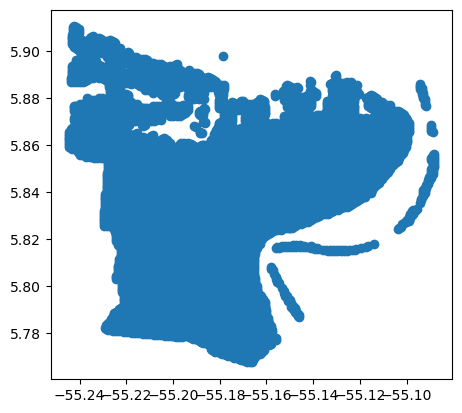

In [20]:
# concatenate origins and destinations to a single gdf

grouped_OD = OD_nodes

gpd.GeoDataFrame(grouped_OD).plot()
# save gdf to geojson
# gpd.GeoDataFrame(grouped_OD).to_file(work_folder.joinpath("paraguay_OD_nodes.geojson"),driver='GeoJSON')
print(len(grouped_OD)*(len(grouped_OD)-1))  # number of OD pairs
print(len(grouped_OD))

grouped_OD['type'] = 'origin'
OD_nodes['type'] = 'origin'
grouped_destinations['type'] = 'destination'


# grouped_OD 
all_OD_nodes = pd.concat([grouped_OD[['type','geometry','vertex_id','population','connected_node_id']], grouped_destinations[['type','geometry','vertex_id','population','connected_node_id']]]).reset_index(drop=True)


In [21]:
all_OD_nodes
grouped_OD_3 = all_OD_nodes

print(grouped_OD_3)


source_vertex_ids = grouped_OD_3[grouped_OD_3['type'] == 'origin']['vertex_id'].values
target_vertex_ids = grouped_OD_3[grouped_OD_3['type'] == 'destination']['vertex_id'].values
OD_vertex_ids = grouped_OD_3['vertex_id'].values

# Time matrix (minutes) for time-weighted accessibility
distance_matrix = np.matrix(graph.distances(
    source=(source_vertex_ids),
    target=(target_vertex_ids),
    weights='time'))
print(distance_matrix)
print(distance_matrix.shape)  # should be (num_origins, num_destinations)
OD_distances_3 = np.where(np.isinf(distance_matrix), 0, distance_matrix)

# Distance matrix (km) for reporting physical distance while keeping time weighting
distance_matrix_km = np.matrix(graph.distances(
    source=(source_vertex_ids),
    target=(target_vertex_ids),
    weights='road_length'))

demand_3 = create_demand_to_Critical_Infra(len(source_vertex_ids), len(target_vertex_ids), OD_distances_3, grouped_OD_3.population.values)
demand_3

              type                   geometry  vertex_id  population  \
0           origin  POINT (-55.16836 5.76788)       5182    4.524825   
1           origin    POINT (-55.167 5.76787)       5183    5.094980   
2           origin  POINT (-55.16633 5.76748)       5192    5.149691   
3           origin  POINT (-55.17106 5.76867)       5184    4.882089   
4           origin  POINT (-55.16971 5.76866)       5187    5.338606   
...            ...                        ...        ...         ...   
18757  destination  POINT (-55.08601 5.88629)      26565    1.000000   
18758  destination  POINT (-55.07215 5.90639)      26566    1.000000   
18759  destination  POINT (-55.24419 5.84791)      26568    1.000000   
18760  destination  POINT (-55.25889 5.84862)      26569    1.000000   
18761  destination  POINT (-55.26184 5.84898)      26570    1.000000   

       connected_node_id  
0            13711487213  
1             1489419459  
2            13711487222  
3            13711487214  


100%|██████████| 18406/18406 [00:03<00:00, 5437.80it/s]


array([[1686, 1686, 1686, ..., 1686, 1686, 1686],
       [1899, 1899, 1899, ..., 1899, 1899, 1899],
       [1919, 1919, 1919, ..., 1919, 1919, 1919],
       ...,
       [1012, 1012, 1012, ..., 1012, 1012, 1012],
       [ 943,  943,  943, ...,  943,  943,  943],
       [1169, 1169, 1169, ..., 1169, 1169, 1169]], shape=(18406, 356))

In [22]:
print(distance_matrix)
distance_origin_to_nearest_Critical_Infra = np.asarray(distance_matrix.min(axis=1)).ravel().astype(float)
# unreachable = no path to any Critical_Infra exists at all, not an actual 0-minute trip
unreachable = ~np.isfinite(distance_origin_to_nearest_Critical_Infra)
distance_origin_to_nearest_Critical_Infra[unreachable] = np.nan
print(distance_origin_to_nearest_Critical_Infra)  # minimum travel time to any Critical_Infra per origin (minutes)
print(len(distance_origin_to_nearest_Critical_Infra))

distance_origin_to_nearest_Critical_Infra_km = np.asarray(distance_matrix_km.min(axis=1)).ravel()
distance_origin_to_nearest_Critical_Infra_km[~np.isfinite(distance_origin_to_nearest_Critical_Infra_km)] = np.nan
print(distance_origin_to_nearest_Critical_Infra_km)  # minimum network distance to any Critical_Infra per origin (km)

# Which Critical_Infra(s) each origin actually connects to (None when unreachable)
nearest_Critical_Infra_idx = np.asarray(distance_matrix.argmin(axis=1)).ravel()
connected_Critical_Infra_ids = grouped_destinations['Critical_Infra_id'].values[nearest_Critical_Infra_idx].astype(object)
connected_Critical_Infra_ids[unreachable] = None

# Store nearest-Critical_Infra travel time (minutes), network distance (km) and connected Critical_Infra id(s)
grouped_OD['time_to_nearest_Critical_Infra_min'] = distance_origin_to_nearest_Critical_Infra
grouped_OD['distance_to_nearest_Critical_Infra_km'] = distance_origin_to_nearest_Critical_Infra_km
grouped_OD['connected_CL'] = connected_Critical_Infra_ids

[[11.83792449 17.64315804 20.41193799 ... 28.5370808  30.41831368
  29.91712253]
 [11.9843445  17.78957804 20.558358   ... 28.6835008  30.56473368
  30.06354254]
 [12.04053845 17.84577199 20.61455194 ... 28.73969475 30.62092763
  30.11973649]
 ...
 [33.07025368 30.28352676 25.84012904 ... 19.79151127 22.08736586
  22.588557  ]
 [33.07025368 30.28352676 25.84012904 ... 19.79151127 22.08736586
  22.588557  ]
 [33.07025368 30.28352676 25.84012904 ... 19.79151127 22.08736586
  22.588557  ]]
[ 1.70586564  1.55944563  1.50325168 ... 11.89476766 11.89476766
 11.89476766]
18406
[0.94736517 0.91465466 0.88968057 ... 5.70001463 5.70001463 5.70001463]


## Running shortest path analysis

In [23]:


OD_vertex_ids = grouped_OD_3.vertex_id.values  # Vertex IDs of the closest network nodes to OD nodes (len = nb of OD nodes)

source_vertex_ids = grouped_OD_3[grouped_OD_3['type'] == 'origin']['vertex_id'].values
target_vertex_ids = grouped_OD_3[grouped_OD_3['type'] == 'destination']['vertex_id'].values

path_edges_id_matrix = run_shortest_path_edges_fast(graph, source_vertex_ids, target_vertex_ids, weight='time')

Computing shortest paths:   7%|▋         | 1361/18406 [00:44<08:54, 31.90it/s]c:\Users\gunaratn\Repos\MS2\scripts\Case_Script\functions.py:52: RuntimeWarning: Couldn't reach some vertices. Location: src/paths/dijkstra.c:555
  edges_path = graph.get_shortest_path(
Computing shortest paths: 100%|██████████| 18406/18406 [09:31<00:00, 32.23it/s]


### Calculating demand

In [24]:
edges["demand_origin_to_Critical_Infra"] = 0.0  
edges['number_of_trips_to_Critical_Infra'] = 0.0
edges["weighted_demand_origin_to_Critical_Infra"] = 0.0
print()


N = len(source_vertex_ids)      # number of origins
K = len(target_vertex_ids)      # number of destinations
print(f"N={N}, K={K}, total OD pairs={N*K}")
print(N+K)

for i in range(N):  # only origins
    # select distances to all destinations for this origin
    distances_to_dest = OD_distances_3[i, :]  # shape (K,)
    
    # find the index of the destination with minimum distance
    j_min_rel = np.argmin(distances_to_dest)  # relative to N..N+K-1
    j_min = j_min_rel                     # absolute index
    
    demand_ij = demand_3[i, j_min]
    
    # if demand_ij == 0:
        # continue
    
    # update all edges along the path
    for edge_id in path_edges_id_matrix[i, 0]:  # only one destination per origin
        edges.iloc[edge_id, edges.columns.get_loc("demand_origin_to_Critical_Infra")] += demand_ij
        edges.iloc[edge_id, edges.columns.get_loc("number_of_trips_to_Critical_Infra")] += 1
        edges.iloc[edge_id, edges.columns.get_loc("weighted_demand_origin_to_Critical_Infra")] += demand_ij * OD_distances_3[i, j_min]

edges.head()


N=18406, K=356, total OD pairs=6552536
18762


,from_id,to_id,u,v,key,highway,lanes,maxspeed,name,oneway,...,width,access,osmid_original,geometry,osm_id,road_length,id,demand_origin_to_Critical_Infra,number_of_trips_to_Critical_Infra,weighted_demand_origin_to_Critical_Infra
0,26743907,4035655956,26743907,4035655956,0,tertiary,2,50,Sir Winston Churchillweg,false,...,nan,nan,4635674,"LINESTRING (-55.16944 5.79112, -55.1695 5.79113)",3,0.006712,0,0.0,0.0,0.0
1,26743927,26744489,26743927,26744489,0,primary,2,40,Latourweg,false,...,nan,nan,423210898,"LINESTRING (-55.17904 5.78669, -55.17887 5.7866)",9,0.021529,1,0.0,0.0,0.0
2,29443940,26743932,26743932,29443940,0,residential,2,40,Kankawastraat,false,...,nan,nan,26836859,"LINESTRING (-55.17563 5.79738, -55.17557 5.797...",20,0.060112,2,0.0,0.0,0.0
3,26743927,26744489,26744489,26743927,0,primary,2,40,Latourweg,false,...,nan,nan,423210898,"LINESTRING (-55.17904 5.78669, -55.17887 5.7866)",22,0.021529,3,107614.0,28.0,0.0
4,26745089,26746037,26745089,26746037,0,primary,2,nan,nan,true,...,7,nan,1343510374,"LINESTRING (-55.17258 5.80626, -55.17261 5.806...",26,0.016384,4,52818.0,8.0,0.0


In [25]:
# max of the new demand columns
print("Max demand_origin_to_Critical_Infra:", edges["demand_origin_to_Critical_Infra"].max())
print("Max number_of_trips_to_Critical_Infra:", edges["number_of_trips_to_Critical_Infra"].max())
print("Max weighted_demand_origin_to_Critical_Infra:", edges["weighted_demand_origin_to_Critical_Infra"].max())


# Aggregate by geometry to remove duplicates while keeping all unique road segments
edges_demand_Critical_Infra = edges.copy()
edges_demand_Critical_Infra['geometry_wkt'] = edges_demand_Critical_Infra.geometry.apply(canonical_geometry_key)

edges_demand_Critical_Infra = edges_demand_Critical_Infra.groupby('geometry_wkt').agg({
    'from_id': 'first',
    'to_id': 'first',
    'geometry': 'first',
    'osm_id': 'first',
    'demand_origin_to_Critical_Infra': 'sum',
    'number_of_trips_to_Critical_Infra': 'sum',
    'weighted_demand_origin_to_Critical_Infra': 'sum'
}).reset_index(drop=True)

edges_demand_Critical_Infra = gpd.GeoDataFrame(edges_demand_Critical_Infra, 
                                        geometry='geometry', crs=edges.crs)

Max demand_origin_to_Critical_Infra: 2824203.0
Max number_of_trips_to_Critical_Infra: 1138.0
Max weighted_demand_origin_to_Critical_Infra: 0.0


In [26]:
gdf_to_rank = edges_demand_Critical_Infra.copy()

# rank first for the demand_origin_to_Critical_Infra
gdf_to_rank['demand_rank'] = gdf_to_rank['demand_origin_to_Critical_Infra'].rank(method='min', ascending=False)
# then for number_of_trips_to_Critical_Infra
gdf_to_rank['trips_rank'] = gdf_to_rank['number_of_trips_to_Critical_Infra'].rank(method='min', ascending=False)
# then for weighted_demand_origin_to_Critical_Infra
gdf_to_rank['weighted_demand_rank'] = gdf_to_rank['weighted_demand_origin_to_Critical_Infra'].rank(method='min', ascending=False)

In [27]:
# Join centroid-level accessibility back to hexagon polygons and save
hexgrid_accessibility = hexgrid.copy()

# grouped_OD shares the same index as hexgrid (it was derived from it)
hexgrid_accessibility = hexgrid_accessibility.merge(
    grouped_OD[['time_to_nearest_Critical_Infra_min', 'distance_to_nearest_Critical_Infra_km', 'connected_CL']],
    left_index=True,
    right_index=True,
    how='left'
)

# Cells with no road within NO_ROAD_ACCESS_DISTANCE_M have no destination to report - use NULL, not a sentinel
hexgrid_accessibility.loc[no_road_access_mask, ['time_to_nearest_Critical_Infra_min', 'distance_to_nearest_Critical_Infra_km']] = np.nan
hexgrid_accessibility.loc[no_road_access_mask, 'connected_CL'] = None

print(hexgrid_accessibility[['population', 'time_to_nearest_Critical_Infra_min', 'distance_to_nearest_Critical_Infra_km']].describe())

         population  time_to_nearest_Critical_Infra_min  \
count  2.013900e+04                        18135.000000   
mean   1.347264e+01                            1.977428   
std    1.210788e+01                            2.097871   
min    1.277588e-07                            0.000000   
25%    4.209894e+00                            0.642655   
50%    1.022586e+01                            1.268868   
75%    1.900856e+01                            2.447500   
max    6.710489e+01                           13.028912   

       distance_to_nearest_Critical_Infra_km  
count                           18135.000000  
mean                                0.996057  
std                                 1.029911  
min                                 0.000000  
25%                                 0.331309  
50%                                 0.648887  
75%                                 1.242495  
max                                 6.514882  


In [28]:
print("Total edges in base_network:", len(base_network))
print("Edges in igraph:", len(edges))  # After graph filtering
print("Edges in edges_demand_Critical_Infra:", len(edges_demand_Critical_Infra))  # After groupby

Total edges in base_network: 39977
Edges in igraph: 122943
Edges in edges_demand_Critical_Infra: 33146


In [29]:
display(hexgrid_accessibility.head())

,cell_id,population,geometry,dist_to_nearest_road_m,time_to_nearest_Critical_Infra_min,distance_to_nearest_Critical_Infra_km,connected_CL
0,"9371,14731",4.524825,"POLYGON ((702800 637827.71, 702775 637871.011,...",173.962033,1.705866,0.947365,80
1,"9373,14731",5.094980,"POLYGON ((702950 637827.71, 702925 637871.011,...",66.903576,1.559446,0.914655,80
2,"9374,14730",5.149691,"POLYGON ((703025 637784.409, 703000 637827.71,...",19.678619,1.503252,0.889681,80
3,"9367,14733",4.882089,"POLYGON ((702500 637914.312, 702475 637957.614...",135.923902,1.120817,0.580204,72
4,"9369,14733",5.338606,"POLYGON ((702650 637914.312, 702625 637957.614...",5.486262,1.222316,0.630954,72


In [30]:

CELL_ID = "9286,15060"

# ── 1. Locate the cell in hexgrid ──────────────────────────────────────────
cell_id_col = next((c for c in hexgrid.columns if 'cell' in c.lower() and 'id' in c.lower()), None)
if cell_id_col:
    mask_cell = hexgrid[cell_id_col].astype(str) == CELL_ID
    cell_row = hexgrid[mask_cell]
    print(f"Found by column '{cell_id_col}':", len(cell_row), "row(s)")
else:
    # fall back: check if the raw string matches any column value
    cell_row = hexgrid[hexgrid.astype(str).apply(lambda r: r.eq(CELL_ID).any(), axis=1)]
    print(f"No 'cell_id' column found. Searched all columns, got {len(cell_row)} row(s).")

if cell_row.empty:
    print("Cell not found in hexgrid at all - check the cell_id value and column name.")
    print("hexgrid columns:", list(hexgrid.columns))
else:
    display(cell_row)
    cell_idx = cell_row.index[0]

    # ── 2. Population filter (must be > 5 to enter OD_nodes) ──────────────
    pop = cell_row['population'].values[0]
    print(f"\n[Step 2] population = {pop}  →  included in OD_nodes? {pop > 5}")

    # ── 3. Distance to nearest road ────────────────────────────────────────
    dist_road = hexgrid.loc[cell_idx, 'dist_to_nearest_road_m'] if 'dist_to_nearest_road_m' in hexgrid.columns else None
    print(f"[Step 3] dist_to_nearest_road_m = {dist_road}  "
          f"(threshold = {NO_ROAD_ACCESS_DISTANCE_M} m, no-access? {no_road_access_mask.loc[cell_idx] if cell_idx in no_road_access_mask.index else 'index not found'})")

    # ── 4. Present in OD_nodes after population filter? ───────────────────
    in_OD = cell_idx in OD_nodes.index
    print(f"[Step 4] cell index {cell_idx} in OD_nodes? {in_OD}")
    if in_OD:
        od_row = OD_nodes.loc[cell_idx]
        print("  OD_nodes row:")
        display(od_row.to_frame().T)

        # ── 5. Did connect_points_to_edges assign a node? ─────────────────
        cn = od_row.get('connected_node_id', None)
        print(f"[Step 5] connected_node_id = {cn}")

        if pd.isna(cn) or cn is None:
            print("  → connect_points_to_edges returned None for this cell.")
            # Show the centroid geometry so we can inspect it visually
            print(f"  Centroid (WGS84): {od_row.geometry}")

            # Find the nearest edge and its distance to understand why snapping may have failed
            cell_metric = gpd.GeoDataFrame([od_row], geometry='geometry', crs=CRS_WGS84).to_crs(CRS_METRIC)
            pt = cell_metric.geometry.values[0]
            edges_m = edges.to_crs(CRS_METRIC)
            sindex = shapely.STRtree(edges_m.geometry.values)
            near_idx = int(sindex.nearest(pt))
            near_edge = edges_m.iloc[near_idx]
            dist_to_edge = pt.distance(near_edge.geometry)
            print(f"  Nearest edge index: {near_idx}, distance: {dist_to_edge:.1f} m")
            print(f"  Nearest edge from_id={near_edge['from_id']}, to_id={near_edge['to_id']}")
        else:
            # ── 6. Is that node id present in the rebuilt graph? ──────────
            in_graph = str(int(cn)) in [str(v) for v in graph.vs['name']]
            print(f"[Step 6] node {cn} found in graph vertices? {in_graph}")
            vi = OD_nodes.loc[cell_idx, 'vertex_id'] if 'vertex_id' in OD_nodes.columns else None
            print(f"         vertex_id after lookup = {vi}  (None → node id not in graph)")


Found by column 'cell_id': 1 row(s)


,cell_id,population,geometry,dist_to_nearest_road_m
19739,"9286,15060",3.986652,"POLYGON ((696425 652073.828, 696400 652117.129...",36.35961



[Step 2] population = 3.986651529380672  →  included in OD_nodes? False
[Step 3] dist_to_nearest_road_m = 36.35961014466475  (threshold = 500 m, no-access? False)
[Step 4] cell index 19739 in OD_nodes? True
  OD_nodes row:


,cell_id,population,geometry,connected_node_id,vertex_id,type,time_to_nearest_Critical_Infra_min,distance_to_nearest_Critical_Infra_km,connected_CL
19739,"9286,15060",3.986652,POINT (-55.22550409736945 5.896871253611718),13711504930,25839,origin,6.134895,2.877788,374


[Step 5] connected_node_id = 13711504930
[Step 6] node 13711504930 found in graph vertices? True
         vertex_id after lookup = 25839  (None → node id not in graph)


### Save outputs

In [31]:
hexgrid_accessibility.to_file(workfolder_test.joinpath('hazard_hexgrid_Critical_Infra_accessibility.gpkg'), driver='GPKG')

In [32]:

connector_nodes_gdf.to_file(workfolder_test.joinpath('hazard_connector_nodes.gpkg'), driver='GPKG')
base_network.to_file(workfolder_test.joinpath('hazard_network_prepared_speed.gpkg'),driver='GPKG')
#origins.to_file(workfolder_test.joinpath('b_origins.gpkg'), driver = 'GPKG')
grouped_OD.to_file(workfolder_test.joinpath("hazard_grouped_OD.gpkg"), driver='GPKG')

edges_demand_Critical_Infra.to_file(workfolder_test.joinpath("hazard_demand.geojson"),driver='GeoJSON')
gdf_to_rank.to_file(workfolder_test.joinpath("hazard_Vulnerability_ranked.geojson"),driver='GeoJSON')




## Distances for each categories

In [33]:
#### Build node lookup for category-wise nearest-node destination assignment
# nodes/graph vertices are aligned via vertex_lookup created after the graph was
# rebuilt with the connector nodes spliced in (see cell above).
nodes = nodes.reset_index(drop=True)
nodes['vertex_id'] = nodes['node_id'].map(vertex_lookup)
nodes = nodes[nodes['vertex_id'].notna()].copy().reset_index(drop=True)

nodes_sindex = shapely.STRtree(nodes.geometry.values)

tqdm.pandas()

print(f"Prepared {len(nodes)} nodes with vertex_id for nearest-node lookups.")


Prepared 8152 nodes with vertex_id for nearest-node lookups.


In [34]:
#### Category-wise Critical_Infra accessibility using helper functions

#### Validate inputs
if 'category' not in Critical_Infra.columns:
    raise KeyError("Expected a 'category' column in Critical_Infra.")

#### Prepare origin nodes (already snapped in previous cells)
origins_cat = OD_nodes[['geometry', 'population', 'vertex_id', 'connected_node_id']].copy()
origins_cat = origins_cat[origins_cat['vertex_id'].notna()].copy()
origins_cat['vertex_id'] = origins_cat['vertex_id'].astype(int)  # vertex_id came from a .map(), leaving float64 dtype that igraph rejects

#### Get Critical_Infra categories
category_values = Critical_Infra['category'].dropna().unique()
print('Categories found:', category_values)

#### Initialize combined hexgrid output
hexgrid_accessibility_by_cat = hexgrid.copy()
hexgrid_accessibility_by_cat['node'] = np.nan
hexgrid_accessibility_by_cat.loc[origins_cat.index, 'node'] = origins_cat['connected_node_id'].values
hexgrid_accessibility_by_cat.loc[no_road_access_mask, 'node'] = np.nan

#### Initialize combined demand output
# geometry_wkt is computed once here (on the full network) and carried through every
# edges.copy() made inside the loop below (accumulate_edge_metrics / aggregate_edges_by_geometry)
# instead of being recomputed from scratch for every category.
if 'geometry_wkt' not in edges.columns:
    edges['geometry_wkt'] = edges.geometry.apply(canonical_geometry_key)
edges_demand_by_cat = edges.groupby('geometry_wkt').agg({
    'from_id': 'first',
    'to_id': 'first',
    'geometry': 'first',
    'osm_id': 'first'
}).reset_index(drop=False)

#### Container for category-level intermediate results
category_results = {}

#### Loop through each category
for cat in category_values:
    print(f"\n--- Processing category: {cat} ---")

    #### 1) Build destinations and snap to graph vertices
    grouped_destinations_cat = prepare_grouped_destinations_for_category(
        Critical_Infra, cat, nodes, nodes_sindex, CRS_WGS84, CRS_METRIC
    )

    if len(grouped_destinations_cat) == 0:
        print(f"No destination vertices for category {cat}, skipping.")
        continue

    #### 2) Compute shortest travel time matrix (origin -> category Critical_Infras)
    source_vertex_ids_cat = origins_cat['vertex_id'].values
    target_vertex_ids_cat = grouped_destinations_cat['vertex_id'].values

    distance_matrix_cat, OD_distances_cat, distance_origin_to_nearest_Critical_Infra_cat = compute_distance_matrices(
        graph, source_vertex_ids_cat, target_vertex_ids_cat
    )

    # unreachable = no path to any Critical_Infra in this category exists at all, not an actual 0-minute trip
    unreachable_cat = ~np.isfinite(distance_origin_to_nearest_Critical_Infra_cat)
    distance_origin_to_nearest_Critical_Infra_cat = distance_origin_to_nearest_Critical_Infra_cat.astype(float)
    distance_origin_to_nearest_Critical_Infra_cat[unreachable_cat] = np.nan

    # Also compute nearest network distance in km while keeping time-weighted routing for demand and paths
    distance_matrix_cat_km = np.matrix(graph.distances(
        source=source_vertex_ids_cat,
        target=target_vertex_ids_cat,
        weights='road_length'
    ))
    distance_origin_to_nearest_Critical_Infra_cat_km = np.asarray(distance_matrix_cat_km.min(axis=1)).ravel()
    distance_origin_to_nearest_Critical_Infra_cat_km[~np.isfinite(distance_origin_to_nearest_Critical_Infra_cat_km)] = np.nan

    #### 3) Assign each origin to nearest Critical_Infra and store time/distance columns
    grouped_OD_cat = origins_cat.copy()
    grouped_OD_cat['time_to_nearest_Critical_Infra_min'] = distance_origin_to_nearest_Critical_Infra_cat
    grouped_OD_cat['distance_to_nearest_Critical_Infra_km'] = distance_origin_to_nearest_Critical_Infra_cat_km

    # Which Critical_Infra(s) each origin connects to in this category (None when unreachable)
    nearest_Critical_Infra_idx_cat = np.asarray(distance_matrix_cat.argmin(axis=1)).ravel()
    connected_ids_cat = grouped_destinations_cat['Critical_Infra_id'].values[nearest_Critical_Infra_idx_cat].astype(object)
    connected_ids_cat[unreachable_cat] = None
    grouped_OD_cat['connected_Critical_Infra_id'] = connected_ids_cat

    cat_slug = category_slug(cat)
    time_col = f"time_nearest_{cat_slug}_min"
    distance_col_km = f"distance_nearest_{cat_slug}_km"
    connected_col = f"connected_{cat_slug}"

    hexgrid_accessibility_by_cat[time_col] = np.nan
    hexgrid_accessibility_by_cat.loc[grouped_OD_cat.index, time_col] = grouped_OD_cat['time_to_nearest_Critical_Infra_min'].values

    hexgrid_accessibility_by_cat[distance_col_km] = np.nan
    hexgrid_accessibility_by_cat.loc[grouped_OD_cat.index, distance_col_km] = grouped_OD_cat['distance_to_nearest_Critical_Infra_km'].values

    hexgrid_accessibility_by_cat[connected_col] = None
    hexgrid_accessibility_by_cat.loc[grouped_OD_cat.index, connected_col] = grouped_OD_cat['connected_Critical_Infra_id'].values

    # Cells with no road within NO_ROAD_ACCESS_DISTANCE_M have no destination to report - use NULL, not a sentinel
    hexgrid_accessibility_by_cat.loc[no_road_access_mask, time_col] = np.nan
    hexgrid_accessibility_by_cat.loc[no_road_access_mask, distance_col_km] = np.nan
    hexgrid_accessibility_by_cat.loc[no_road_access_mask, connected_col] = None

    #### 4) Build demand matrix and shortest paths using existing functions
    demand_cat = create_demand_to_Critical_Infra(
        len(source_vertex_ids_cat),
        len(target_vertex_ids_cat),
        OD_distances_cat,
        grouped_OD_cat.population.values
    )

    path_edges_id_matrix_cat = run_shortest_path_edges_fast(
        graph,
        source_vertex_ids_cat,
        target_vertex_ids_cat,
        weight='time'
    )

    #### 5) Push trips/demand onto edges
    edges_cat = accumulate_edge_metrics(edges, path_edges_id_matrix_cat, OD_distances_cat, demand_cat)

    #### 6) Aggregate category demand and append category-specific columns
    edges_demand_Critical_Infra_cat = aggregate_edges_by_geometry(edges_cat)

    edges_demand_by_cat, demand_col, trips_col, weighted_col = append_category_metrics(
        edges_demand_by_cat, edges_demand_Critical_Infra_cat, cat_slug
    )

    category_results[cat] = {
        'distance_matrix': distance_matrix_cat,
        'distance_matrix_km': distance_matrix_cat_km,
        'grouped_OD': grouped_OD_cat,
        'grouped_destinations': grouped_destinations_cat,
        'time_column': time_col,
        'distance_column_km': distance_col_km,
        'connected_column': connected_col,
        'demand_column': demand_col,
        'trips_column': trips_col,
        'weighted_demand_column': weighted_col,
    }

    print(f"Category '{cat}' complete: {len(grouped_destinations_cat)} destinations")

#### Save combined outputs
hexgrid_out = workfolder_test.joinpath("hazard_cat_hexgrid_Critical_Infra_accessibility.gpkg")
hexgrid_accessibility_by_cat.to_file(hexgrid_out, driver='GPKG')

edges_out = workfolder_test.joinpath("hazard_cat_b_demand.geojson")
edges_demand_by_cat = gpd.GeoDataFrame(edges_demand_by_cat, geometry='geometry', crs=edges.crs)
edges_demand_by_cat.drop(columns=['geometry_wkt']).to_file(edges_out, driver='GeoJSON')

#### Summary
print('Saved combined hexgrid:', hexgrid_out)
print('Saved combined demand:', edges_out)
print(f"\nFinished category processing for {len(category_results)} categories.")

Categories found: ['supermarket' 'school' 'highway_bus_stop' 'hospital']

--- Processing category: supermarket ---


Computing shortest paths:   7%|▋         | 1362/18406 [00:51<10:49, 26.25it/s]c:\Users\gunaratn\Repos\MS2\scripts\Case_Script\functions.py:52: RuntimeWarning: Couldn't reach some vertices. Location: src/paths/dijkstra.c:555
  edges_path = graph.get_shortest_path(
Computing shortest paths: 100%|██████████| 18406/18406 [11:28<00:00, 26.75it/s]


Category 'supermarket' complete: 217 destinations

--- Processing category: school ---


Computing shortest paths:   7%|▋         | 1363/18406 [00:53<11:12, 25.34it/s]c:\Users\gunaratn\Repos\MS2\scripts\Case_Script\functions.py:52: RuntimeWarning: Couldn't reach some vertices. Location: src/paths/dijkstra.c:555
  edges_path = graph.get_shortest_path(
Computing shortest paths: 100%|██████████| 18406/18406 [11:30<00:00, 26.67it/s]


Category 'school' complete: 80 destinations

--- Processing category: highway_bus_stop ---


Computing shortest paths:   7%|▋         | 1361/18406 [00:57<10:10, 27.91it/s]c:\Users\gunaratn\Repos\MS2\scripts\Case_Script\functions.py:52: RuntimeWarning: Couldn't reach some vertices. Location: src/paths/dijkstra.c:555
  edges_path = graph.get_shortest_path(
Computing shortest paths: 100%|██████████| 18406/18406 [11:36<00:00, 26.43it/s]


Category 'highway_bus_stop' complete: 30 destinations

--- Processing category: hospital ---


Computing shortest paths:   7%|▋         | 1364/18406 [00:47<10:14, 27.72it/s]c:\Users\gunaratn\Repos\MS2\scripts\Case_Script\functions.py:52: RuntimeWarning: Couldn't reach some vertices. Location: src/paths/dijkstra.c:555
  edges_path = graph.get_shortest_path(
Computing shortest paths: 100%|██████████| 18406/18406 [09:45<00:00, 31.44it/s]


Category 'hospital' complete: 5 destinations
Saved combined hexgrid: P:\11212759-001-brs\002-Kaartverhal_KEA\MS2\MS2proposal\data\paramaribo\outputs_ver04\outputs\hazard_cat_hexgrid_Critical_Infra_accessibility.gpkg
Saved combined demand: P:\11212759-001-brs\002-Kaartverhal_KEA\MS2\MS2proposal\data\paramaribo\outputs_ver04\outputs\hazard_cat_b_demand.geojson

Finished category processing for 4 categories.
